## Inputs
- High-resolution SMB map by Noël et al.
- [data/target_grid_mask.nc](data/target_grid_mask.nc)  
(+ MODIS for visualisation only)

## Outputs
- SMB map, interpolated to target grid, added to [data/fluxnet_div_ross.nc](data/fluxnet_div_ross.nc]) for side-by-side comparison

In [1]:
# use fluxnet_env specified in the environment.yml file
import numpy as np
import pandas as pd
import torch
from pyproj import CRS, Transformer
import xarray as xr
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import os

In [2]:
from regions import ROSS_BOUNDS

x_min = ROSS_BOUNDS["x_min"]
x_max = ROSS_BOUNDS["x_max"]
y_min = ROSS_BOUNDS["y_min"]
y_max = ROSS_BOUNDS["y_max"]

# Load data

We use interpolated [Higher Antarctic ice sheet accumulation and surface melt rates revealed at 2 km resolution from Zenodo](https://zenodo.org/records/10007855)
(filename: smb_rec.1979-2021.BN_RACMO2.3p2_ANT27_ERA5-3h.AIS.2km.YY.nc)

Reference:
- *Noël, Brice, et al. "Higher Antarctic ice sheet accumulation and surface melt rates revealed at 2 km resolution." Nature communications 14.1 (2023): 7949.*

**smb_rec.1979-2021.BN_RACMO2.3p2_ANT27_ERA5-3h.AIS.2km.YY.nc**: map of annual SMB (kg per m² or mm w.e. per year) from ERA5-forced RACMO2.3p2 at 27 km, statistically downscaled to 2 km resolution, covering the whole of Antarctica (1979-2021).

In [3]:
from paths import path_to_smb

path_to_folder = path_to_smb
# load dataset
smb = xr.load_dataset(path_to_folder)
# insepct
print(smb.smb_rec.values.shape)

(43, 2303, 2778)


## Units

| Field    | Description                                                                           |
| -------- | ------------------------------------------------------------------------------------- |
| `time`   | 1979–2021 (yearly data)                                                               |
| `x`, `y` | Already in Antarctic Polar Stereographic Projection [EPSG:3031](https://epsg.io/3031) |
| `smb`    | **mm w.e. per year**                                                                  |


# Subset area

In [4]:
# Using Ross bounds
smb_ross = smb.sel(
    x = slice(x_min, x_max),
    y = slice(y_min, y_max),
)

smb_ross

<xarray.Dataset> Size: 43MB
Dimensions:  (time: 43, x: 500, y: 501)
Coordinates:
  * time     (time) datetime64[ns] 344B 1979-06-30T18:00:00 ... 2021-06-30T18...
  * x        (x) float32 2kB -5.99e+05 -5.97e+05 -5.95e+05 ... 3.97e+05 3.99e+05
  * y        (y) float32 2kB -1.4e+06 -1.398e+06 -1.396e+06 ... -4.02e+05 -4e+05
Data variables:
    smb_rec  (time, y, x) float32 43MB 0.0 0.0 0.0 0.0 ... 10.81 10.9 11.39
Attributes:
    CDI:          Climate Data Interface version 2.2.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    grid:         Map Projection: Antarctic Polar Stereographic EPSG3031 - Ma...
    netcdf:       4.7.4 of Apr 18 2020 10:56:44 $
    frequency:    mon
    CDO:          Climate Data Operators version 2.2.2 (https://mpimet.mpg.de...
    institution:  IMAU/ULiège (Brice Noël)
    NCO:          netCDF Operators version 5.1.7 (Homepage = http://nco.sf.ne...
    title:        Annual SMB field at 2km (RACMO2.3p2) ERA

### Uncertainty analysis

In [36]:
smb_ross_spatial_mean = smb_ross.mean(dim = ["x", "y"]) 
smb_ross_spatial_mean_annual_mean = smb_ross_spatial_mean.smb_rec.values.mean()
print(smb_ross_spatial_mean_annual_mean) # in mm
print("1979 - 2021 Mean (in m): ", smb_ross_spatial_mean_annual_mean / 1000)
smb_ross_spatial_mean_annual_std = smb_ross_spatial_mean.smb_rec.values.std(ddof = 1)
print("One std deviation (in m): ", smb_ross_spatial_mean_annual_std/1000) # in mm

98.31248
1979 - 2021 Mean (in m):  0.098312475
One std deviation (in m):  0.022301013


# Average over years

In [5]:
min_year = 1994
max_year = 2018

# select years
smb_ross_span = smb_ross.sel(time = slice(f"{min_year}-01-01", f"{max_year}-12-31"))
# compute longterm mean
smb_ross_longterm_mean = smb_ross_span.mean(dim = ("time"))

# Plot

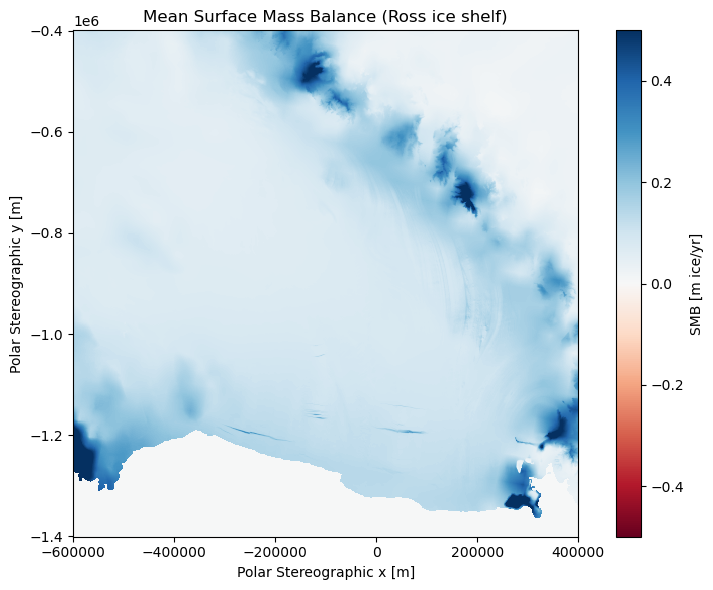

In [6]:
# Determine symmetric color limits around zero
vmax = 0.5
vmin = - 0.5

# Plot
plt.figure(figsize = (8, 6))
pcm = plt.pcolormesh(
    smb_ross_longterm_mean.x,
    smb_ross_longterm_mean.y,
    smb_ross_longterm_mean.smb_rec / 1000,  # convert from mm to m
    cmap = "RdBu",
    vmin = vmin,
    vmax = vmax,
    shading = "auto"    
)
plt.colorbar(pcm, label = "SMB [m ice/yr]")
plt.title("Mean Surface Mass Balance (Ross ice shelf)")
plt.xlabel("Polar Stereographic x [m]")
plt.ylabel("Polar Stereographic y [m]")
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

# Interpolate at target grid

In [7]:
# Load target grid
target_grid_mask = xr.load_dataset("data/target_grid_mask.nc")

# Interpolate smb onto the target grid's x/y
smb_on_target = smb_ross_longterm_mean.interp(
    x = target_grid_mask["x"],
    y = target_grid_mask["y"],
    # Note: cubic had issues
    method = "linear",
)

# Add mask from target grid as second variable
smb_on_target["mask"] = target_grid_mask.mask

In [8]:
smb_masked = smb_on_target.smb_rec.where(smb_on_target["mask"] > 0)

In [20]:
# Integrate over the masked area to get total SMB in m^3/yr
# Count the number of grid cells that are not masked
num_cells = smb_masked.count().values
# Calculate the area of each grid cell (assuming uniform grid spacing)
dx = np.diff(smb_on_target.x.values)[0]
dy = np.diff(smb_on_target.y.values)[0]
cell_area = np.abs(dx * dy)  # in m^2
# Total area of unmasked cells
total_area = num_cells * cell_area  # in m^2
# about 487,000 km² indeed
# Total SMB in m^3/yr
total_smb_m3_per_yr = (smb_masked.mean().values / 1000) * total_area # convert from mm to m and multiply by area
print(f"Mean SMB: {smb_masked.mean().values / 1000} m/yr")
# Mean is 11 cm 
print(f"Total SMB: {total_smb_m3_per_yr}")

Mean SMB: 0.10949454456567764 m/yr
Total SMB: 53446394972.49015


In [ ]:
# Plot
plt.figure(figsize = (8, 6))
pcm = plt.pcolormesh(
    smb_masked.x,
    smb_masked.y,
    smb_masked / 1000,  # convert from mm to m
    cmap = "RdBu",
    vmin = vmin,
    vmax = vmax,
    shading = "auto"    
)
plt.colorbar(pcm, label = "SMB [m ice/yr]")
plt.title("Mean Surface Mass Balance (Ross ice shelf)")
plt.xlabel("Polar Stereographic x [m]")
plt.ylabel("Polar Stereographic y [m]")
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

# Load MODIS background

In [ ]:
from paths import path_to_modis
modis_ross = torch.load(path_to_modis, weights_only = False)
modis_ross.shape

In [ ]:
vis_again = True

# Only rerun if needed
if vis_again :
    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[2],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
    )

    # 2) SMB on top (draw second)
    pcm = ax.pcolormesh(
    smb_masked.x,
    smb_masked.y,
    # mm -> m
    # (Ny, Nx)
    smb_masked / 1000,
    cmap = "RdBu",
    vmin = -3.0,
    vmax = 3.0,
    shading = "auto",
    # 1.0 for full opacity & consistency
    alpha = 1.0,
    zorder = 1,
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

    fig.savefig("figures/smb_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
    plt.show()

# Add to combined xarray dataset

In [ ]:
# Generated in train_fluxnet_on_all_data.ipynb
path = "data/fluxnet_div_ross.nc"

# 1) Open -> load into memory -> close file handle
with xr.open_dataset(path) as _ds:
    ds = _ds.load()

# 2) Add Noël SMB (convert mm -> m)
ds["noel_smb"] = (("y", "x"), (smb_masked / 1000.0).values.T)
ds["noel_smb"].attrs.update({
    "long_name": "Noël surface mass balance (SMB) on target grid",
    "units": "m yr-1",
    "note": "Converted from mm yr-1 to m yr-1 by dividing by 1000",
})

# 3) Safe overwrite to SAME pathname (write temp, then atomic replace)
tmp_path = path + ".tmp"
ds.to_netcdf(tmp_path, mode = "w")
os.replace(tmp_path, path)